In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math
import matplotlib.patches as mpatches

In [44]:
df = pd.read_csv("Cleaned_ships_data.csv") # df - DataFrame 

In [47]:
avg_dwt_by_length = df.groupby("length")["dwt"].mean().reset_index()
avg_dwt_by_length.head()


,length,dwt
0,272,8200.0
1,277,82960.0
2,280,74894.0
3,282,175775.0
4,284,75008.5


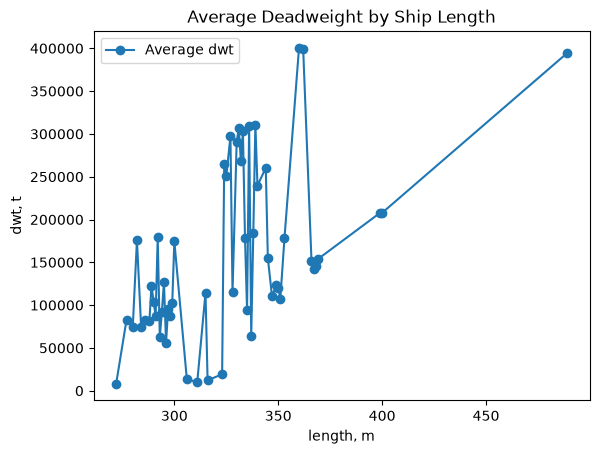

In [56]:
fig, ax = plt.subplots()
ax.plot(avg_dwt_by_length["length"], avg_dwt_by_length["dwt"],marker="o", label="Average dwt")
ax.set_xlabel("length, m")
ax.set_ylabel("dwt, t")
ax.legend()
ax.set_title("Average Deadweight by Ship Length")
plt.show()

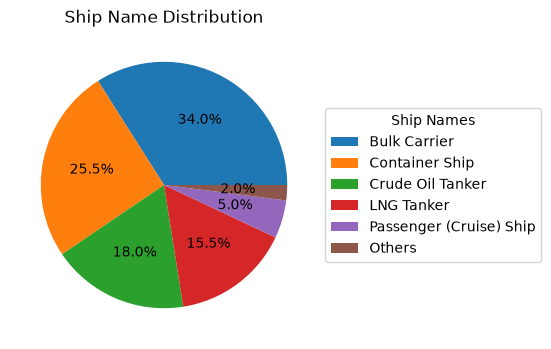

In [ ]:
OTHERS_MAX_COUNT = 2
PIE_FIGSIZE = (4,4)

count_names = df["ship_name"].value_counts()
mask = count_names <= OTHERS_MAX_COUNT # массив тру фолз 
pie_data = count_names[~mask].copy()
pie_data["Others"] = count_names[mask].sum()

fig, ax = plt.subplots(figsize=PIE_FIGSIZE)
ax.set_title("Ship Name Distribution")
ax.pie(pie_data.values, autopct="%1.1f%%")
ax.legend(pie_data.index, title="Ship Names", loc = "center left", bbox_to_anchor=(1, 0.5))
plt.show()


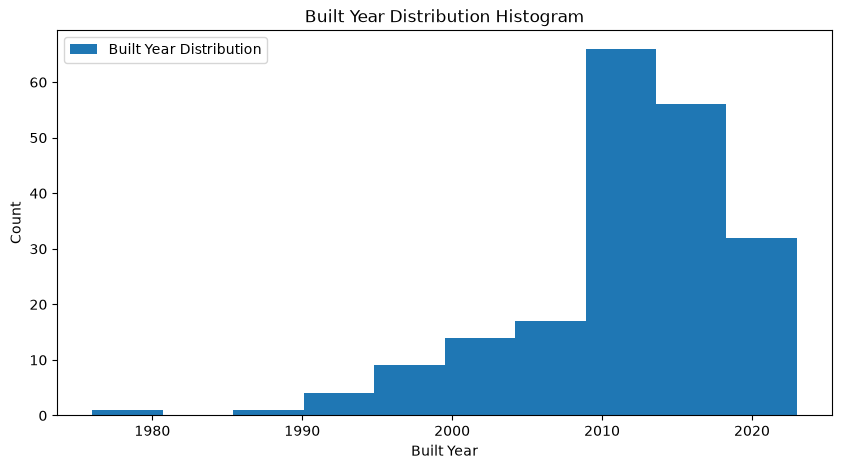

In [59]:
HIST_FIGSIZE = (10, 5)
YEAR_STEP = 5
cols = math.ceil((df["built_year"].max() - df["built_year"].min()) / YEAR_STEP)
fig, ax = plt.subplots(figsize = HIST_FIGSIZE)
ax.hist(df["built_year"], bins=cols, label="Built Year Distribution")
ax.set_xlabel("Built Year")
ax.set_ylabel("Count")
ax.set_title("Built Year Distribution Histogram")
ax.legend()
plt.show()




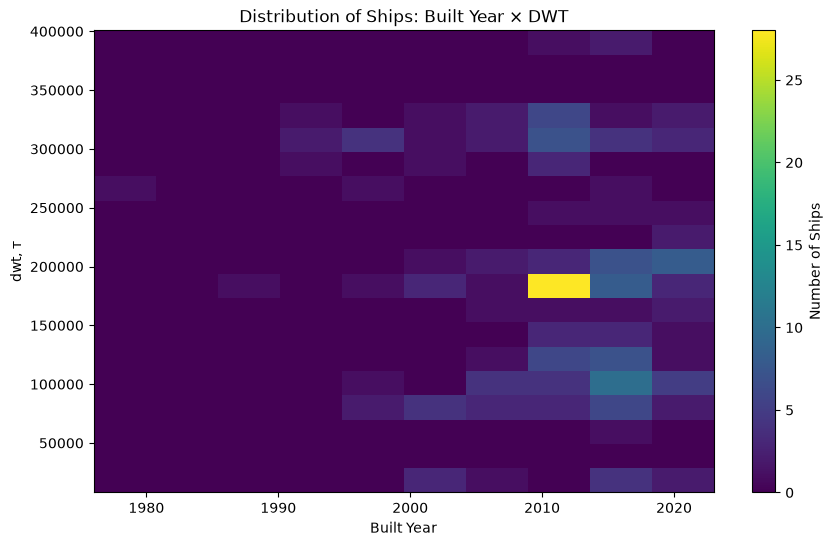

In [ ]:
DWT_BINS = 20
HIST2D_FIGSIZE = (10, 6)

dwt_edges = np.linspace(df["dwt"].min(), df["dwt"].max(), DWT_BINS + 1) # границы от минимума до максимума с заданным шагом по условию 

fig, ax = plt.subplots(figsize=HIST2D_FIGSIZE)
hist = ax.hist2d(df["built_year"], df["dwt"], bins=[cols, dwt_edges])
fig.colorbar(hist[3], ax=ax, label="Number of Ships")
ax.set_xlabel("Built Year")
ax.set_ylabel("dwt, т")
ax.set_title("Distribution of Ships: Built Year × DWT")
plt.show()

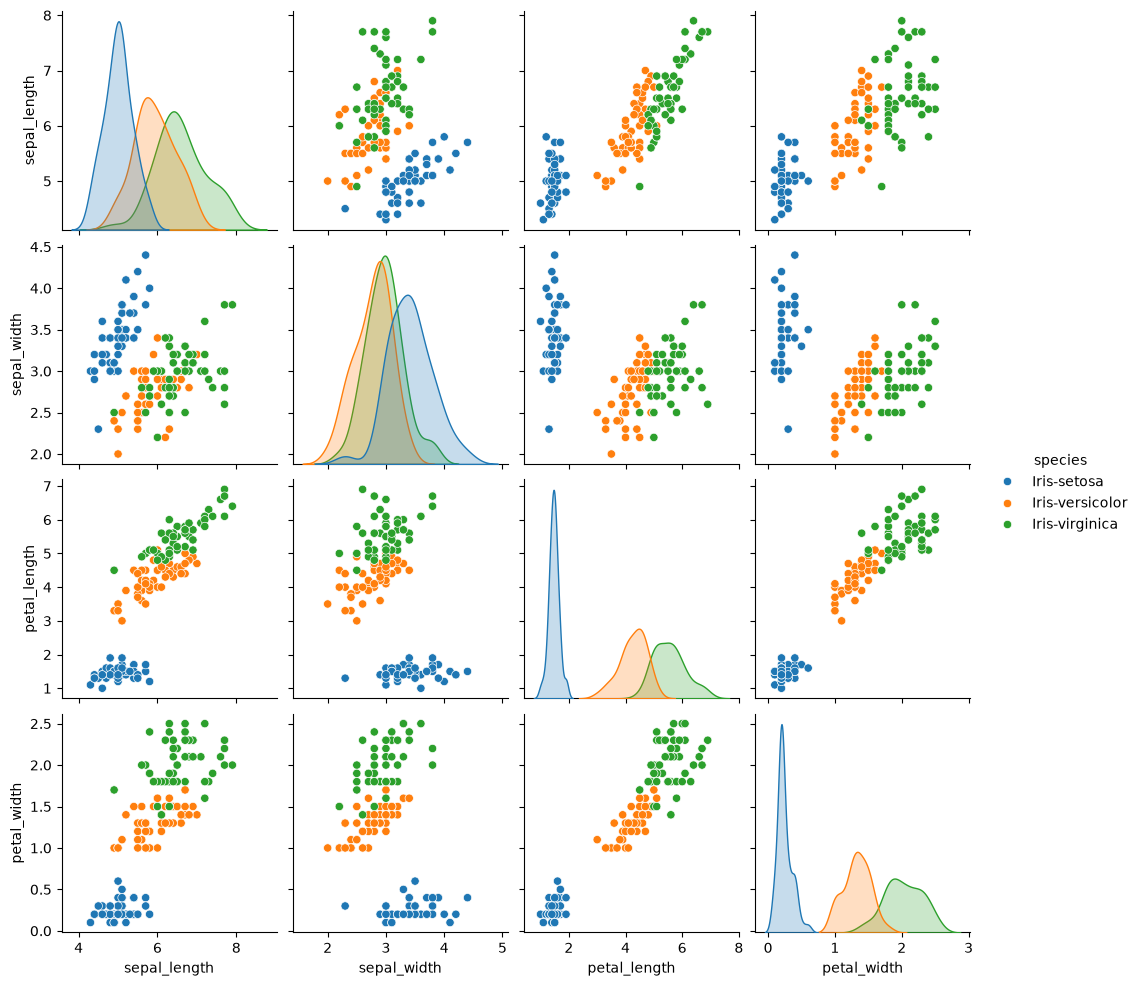

In [52]:
iris = pd.read_csv("IRIS.csv")
sns.pairplot(iris, hue="species") # раскарсим точки по видам 
plt.show()

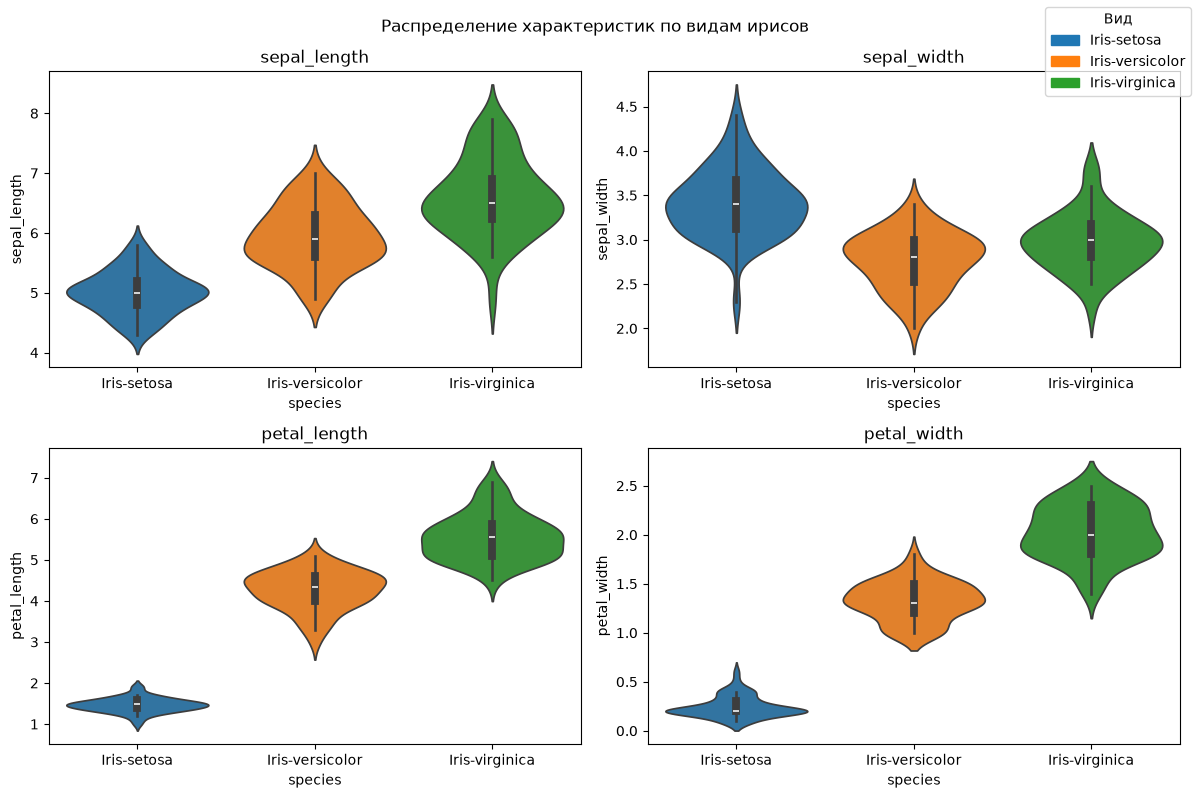

In [ ]:
FEATURES = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
VIOLIN_FIGSIZE = (12, 8)

fig, axes = plt.subplots(2, 2, figsize=VIOLIN_FIGSIZE)
axes = axes.flatten() # вместо матрицы линейный массивчик 

for i, feature in enumerate(FEATURES):
    sns.violinplot(data=iris, x="species", y=feature, hue="species", ax=axes[i])
    axes[i].set_title(feature)

species_list = iris["species"].unique()
palette = sns.color_palette(n_colors=len(species_list)) 
handles = []
for i, name in enumerate(species_list):
    handles.append(mpatches.Patch(color=palette[i], label=name)) # create square for legend
fig.legend(handles=handles, title="Species", loc="upper right")

fig.suptitle("Distribution of Iris Features by Species")
fig.tight_layout() # раздвигает графики чтобы не наезжали 
plt.show()